# Week 5
For Week 5, include concepts such as support vector machines, the kernel trick, and regularization for support vector machines. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday. 

##### Import Libraries

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import optuna
from optuna.visualization import (
    plot_optimization_history, 
    plot_param_importances, 
    plot_parallel_coordinate
)

from sklearn.metrics import recall_score

##### Load Data

In [2]:
diabetes_indicators = pd.read_csv('Modified_Datasets/diabetes_indicators_2.csv')

In [3]:
cervical_cancer = pd.read_csv('Modified_Datasets/cervical_cancer_2.csv')

##### SVMs/Kernel Trick/Regularization

**Diabetes**

In [4]:
# X, y
Xd = diabetes_indicators.drop('Diabetes_012', axis = 1)
yd = diabetes_indicators['Diabetes_012']
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size = 0.2, random_state = 42)

In [5]:
# Scaling
scaler = StandardScaler()

In [6]:
# Transform
Xd_train_scaled = scaler.fit_transform(Xd_train)
Xd_test_scaled = scaler.transform(Xd_test)

In [7]:
kf = KFold(n_splits = 3,
           shuffle = True,
           random_state = 42)

In [8]:
# Kernel utilizes the kernel trick; C is regularization term
# Skipping hyperparameter tuning due to extensive tuning time
svmd = SVC(kernel = 'rbf', C = 1.0)

In [9]:
cv_scores_svmd = cross_val_score(
    svmd, 
    Xd_train_scaled, 
    yd_train, 
    cv = kf, 
    scoring = 'recall_weighted'
)

In [10]:
print(cv_scores_svmd.mean())

0.832796594186309


**Cervical Cancer**

In [24]:
# X, y
Xc = cervical_cancer.drop('Dx:Cancer', axis = 1)
yc = cervical_cancer['Dx:Cancer']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.2, random_state = 42)

In [25]:
# Scaler
scaler = StandardScaler()

In [26]:
# Transform
Xc_train_scaled = scaler.fit_transform(Xc_train)
Xc_test_scaled = scaler.transform(Xc_test)

In [27]:
# Kernel utilizes the kernel trick; C is regularization term
# Create an objective function
def cobjective_function(trial): 
    params = {
        'kernel': 'rbf',
        'C': trial.suggest_float('C', 1e-3, 1e3, log = True)  
}

    svmc = SVC(**params)

    cv_scores_svmc = cross_val_score(
        svmc, 
        Xc_train_scaled, 
        yc_train, 
        cv = kf, 
        scoring = 'recall'
    )

    return cv_scores_svmc.mean()

In [28]:
# Set up Optuna study

cstudy = optuna.create_study(direction = 'maximize')

cstudy.optimize(cobjective_function, n_trials = 3)

[I 2026-10-17 08:03:00,975] A new study created in memory with name: no-name-c373bb1a-2136-4406-959c-346512a721b5
[I 2026-10-17 08:03:01,010] Trial 0 finished with value: 0.6428571428571429 and parameters: {'C': 516.4120847606727}. Best is trial 0 with value: 0.6428571428571429.
[I 2026-10-17 08:03:01,039] Trial 1 finished with value: 0.6428571428571429 and parameters: {'C': 69.70094138642632}. Best is trial 0 with value: 0.6428571428571429.
[I 2026-10-17 08:03:01,055] Trial 2 finished with value: 0.0 and parameters: {'C': 0.001969022285263563}. Best is trial 0 with value: 0.6428571428571429.


In [29]:
# Display results

cresults = cstudy.trials_dataframe()

cresults = cresults.sort_values(by = 'value', ascending = False)

display(cresults.head(5))

,number,value,datetime_start,datetime_complete,duration,params_C,state
0,0,0.642857,2026-10-17 08:03:00.975858,2026-10-17 08:03:01.010157,0 days 00:00:00.034299,516.412085,COMPLETE
1,1,0.642857,2026-10-17 08:03:01.010157,2026-10-17 08:03:01.039025,0 days 00:00:00.028868,69.700941,COMPLETE
2,2,0.000000,2026-10-17 08:03:01.039025,2026-10-17 08:03:01.055503,0 days 00:00:00.016478,0.001969,COMPLETE


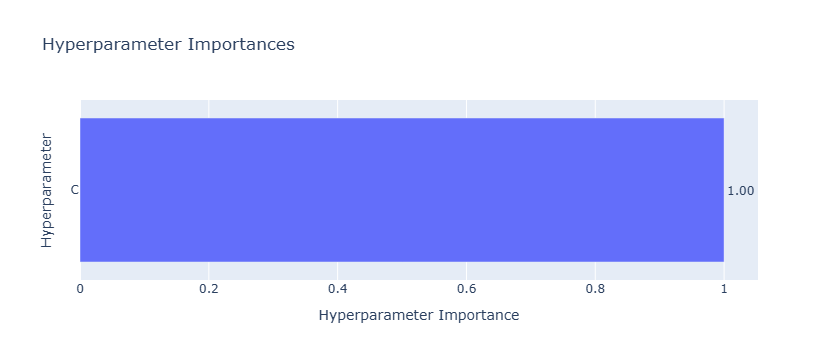

In [33]:
# Plot of which hyperparameters were the most important
plot_param_importances(cstudy).show()

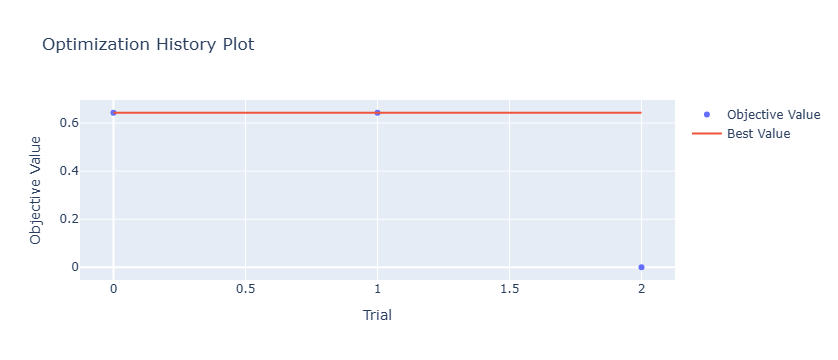

In [34]:
plot_optimization_history(cstudy).show()

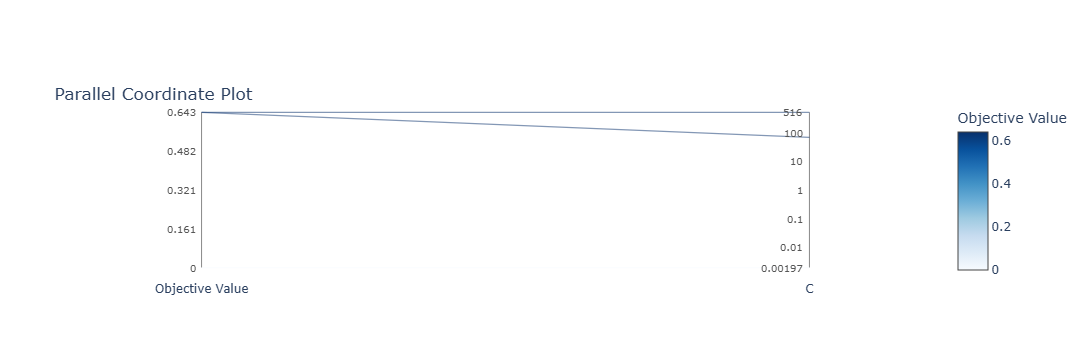

In [35]:
plot_parallel_coordinate(cstudy).show()